# Proyecto 2: predecir y agrupar

Entrega: **viernes 16 de octubre** · 10 puntos

| Criterio | Pts | Qué buscamos |
|---|---|---|
| Preparación y validación | 3 | El test se toca una sola vez; nada se filtra al modelo |
| Búsqueda de opciones y ensamble | 2 | Probaron opciones con razón, no al azar |
| Métrica e interpretación | 2 | Dicen por qué esa métrica y dónde se equivoca el modelo |
| Análisis sin respuestas | 2 | Cada grupo o eje tiene nombre y descripción |
| Límites | 1 | Qué no se puede concluir |

## 1. Pregunta y datos

Los clubes, los scouts y las plataformas de fantasy football necesitan anticipar cuántos goles anotará un jugador la temporada siguiente: sirve para decidir una renovación, el precio de un fichaje o a quién alinear. Este proyecto continúa el Proyecto 1 (donde se predijeron esos goles con un baseline) y lo lleva más lejos: validación sin fugas, un ensamble con búsqueda razonada y un análisis de grupos que explica **en qué tipo de jugador falla más el modelo**. Si el error se concentra en un tipo de jugador, ese es el segmento donde la predicción no debería usarse sin criterio humano.

**Pregunta:** con las estadísticas de una temporada de un jugador de élite (partidos, goles, asistencias, rating y, si existe, la temporada previa), ¿cuántos goles anotará en la temporada siguiente, y en qué perfil de jugador se equivoca más el modelo?

**Tipo de problema:** predecir un número (regresión)

**Columna que se quiere predecir:** `Goals_next` (goles del jugador en la temporada N+1)

**Fuente, fecha de descarga y licencia:** Kaggle — *"Football Players Datasets 2015-2024"*, subido por el usuario abdulmalik1518 https://www.kaggle.com/datasets/abdulmalik1518/football-players-datasets-2015-2024 · descargado el 07-09-2026 · licencia Apache 2.0.

**Qué representa una fila:** un jugador en una temporada N, con sus estadísticas de esa temporada, las de la temporada previa (si existe) y, como objetivo, sus goles en la temporada N+1. Son 1038 filas de 165 jugadores de élite, con temporadas de inicio entre 2014 y 2023.

**Qué hacemos distinto respecto al Proyecto 1:**

- **Validación:** el corte train/test es por temporada (antes era aleatorio) y la validación cruzada se agrupa por jugador, para que un mismo jugador no quede a la vez en entrenamiento y validación.
- **Variables:** se agregan goles y asistencias de la temporada previa, goles por partido y el equipo (agrupando los poco frecuentes). Además se **quita** `cambio_equipo`, que en el Proyecto 1 se construía con el equipo de la temporada que se quiere predecir y no hay garantía de que se conozca al momento de predecir.
- **Modelado:** se agrega un ensamble (bosque aleatorio) con búsqueda de opciones, comparado contra un modelo tonto y uno simple.
- **Análisis sin respuestas:** se agrupan los jugadores con k-Means y se cruzan los grupos con el error del modelo.

Los números de test del Proyecto 1 y de este proyecto **no son comparables**: el test es distinto (aleatorio vs. las temporadas más recientes) y las variables también.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42

# Cargar el dataset 
raw = pd.read_csv('Latest_Football__Players_2024_Data.csv')
raw = raw.drop_duplicates()

# Año de inicio de la temporada, para ordenar cronológicamente
raw['anio'] = raw['Seasons'].str[:4].astype(int)
raw = raw.sort_values(['Players', 'anio']).reset_index(drop=True)

# Temporada siguiente (solo para el target) y anterior (feature nuevo) del mismo jugador
g = raw.groupby('Players')
raw['Goals_next'] = g['Goals'].shift(-1)
raw['anio_next'] = g['anio'].shift(-1)
raw['Goals_prev'] = g['Goals'].shift(1)
raw['Assists_prev'] = g['Assists'].shift(1)
raw['anio_prev'] = g['anio'].shift(1)

# La temporada previa solo cuenta si es la inmediatamente anterior;
# si no existe (primera temporada registrada en el dataset, o hueco), queda como NaN
# y se imputa dentro del Pipeline
sin_prev = raw['anio_prev'] != raw['anio'] - 1
raw.loc[sin_prev, ['Goals_prev', 'Assists_prev']] = np.nan

# Pares consecutivos N -> N+1
df = raw[raw['anio_next'] == raw['anio'] + 1].copy()
df['goles_por_partido'] = df['Goals'] / df['Matches']

# Control: el año de inicio no debe repetirse para un mismo jugador
# (unas pocas temporadas vienen mal escritas, p. ej. '2016/1017', pero el año inicial es válido)
assert not raw.duplicated(['Players', 'anio']).any()

df = df[['Players', 'Teams', 'anio', 'Matches', 'Goals', 'Assists',
         'Seasons Ratings', 'goles_por_partido', 'Goals_prev', 'Assists_prev',
         'Goals_next']].reset_index(drop=True)
df.head()

,Players,Teams,anio,Matches,Goals,Assists,Seasons Ratings,goles_por_partido,Goals_prev,Assists_prev,Goals_next
0,Adrien Rabiot,PSG,2016,39,4,4,7.4,0.102564,NaN,NaN,5.0
1,Adrien Rabiot,PSG,2017,50,5,7,7.1,0.100000,4.0,4.0,2.0
2,Adrien Rabiot,PSG,2018,20,2,2,7.4,0.100000,5.0,7.0,1.0
3,Adrien Rabiot,Juventus,2019,37,1,1,6.9,0.027027,2.0,2.0,5.0
4,Adrien Rabiot,Juventus,2020,47,5,3,7.2,0.106383,1.0,1.0,0.0


## 2. Mirada rápida a los datos

In [2]:
print(df.shape)
df.info()
print()
print('Fracción de huecos por columna:')
print(df.isna().mean().round(3))
print()
print(df['Goals_next'].describe())
print()
print('Pares por temporada de inicio:')
print(df['anio'].value_counts().sort_index())

(1038, 11)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1038 entries, 0 to 1037
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Players            1038 non-null   object 
 1   Teams              1038 non-null   object 
 2   anio               1038 non-null   int64  
 3   Matches            1038 non-null   int64  
 4   Goals              1038 non-null   int64  
 5   Assists            1038 non-null   int64  
 6   Seasons Ratings    1038 non-null   float64
 7   goles_por_partido  1038 non-null   float64
 8   Goals_prev         871 non-null    float64
 9   Assists_prev       871 non-null    float64
 10  Goals_next         1038 non-null   float64
dtypes: float64(5), int64(4), object(2)
memory usage: 89.3+ KB

Fracción de huecos por columna:
Players              0.000
Teams                0.000
anio                 0.000
Matches              0.000
Goals                0.000
Assists              0.000


**Lo que importa de este dataset para modelar:**

1. **Hay fechas y jugadores repetidos.** Son 1038 filas de 165 jugadores, y cada jugador aparece en varias filas (una por cada par de temporadas consecutivas, entre 2014 y 2023). Barajar las filas dejaría entrenar con temporadas futuras y mezclaría al mismo jugador entre train y test, así que hay que cortar por temporada y agrupar por jugador en la validación.
2. **Los únicos huecos son la temporada previa.** Las columnas originales no tienen nulos, pero `Goals_prev` y `Assists_prev` faltan en 167 filas (16.1%) porque no hay registro de la temporada inmediatamente anterior. 105 de esas 167 están en 2014-2016, es decir, son la primera temporada que el dataset registra de un jugador (no un debut real: el dataset simplemente no ve su pasado). La falta depende del año de inicio del dataset, que sí observamos, y no del valor de los goles (MAR), así que se imputa con la mediana de train y se agrega una columna que avisa que no había temporada previa.
3. **La columna a predecir es asimétrica.** `Goals_next` tiene mediana 5, media 8.25 y máximo 55, con cola larga a la derecha. Pocas temporadas de goleadores extremos concentran gran parte del error posible, lo que pesa para elegir la métrica y para comparar contra el modelo tonto (que predice siempre la media).
4. **La temporada viene mal escrita en pocos casos.** 5 de las 1208 filas (0.4%, tras quitar 8 duplicados exactos) tienen un formato irregular (por ejemplo `2016/1017`, `2017/2017` o solo el año). Se toma el año de inicio (los primeros cuatro caracteres) y el código comprueba que ningún jugador repite año de inicio, así que no se crean pares falsos.

## 3. Separar y preparar

In [3]:
# Los datos tienen fechas: se corta por temporada, no se baraja.
# Train = pares con temporada de inicio <= 2020; Test = de 2021 en adelante (lo más reciente).
CORTE = 2020
es_train = df['anio'] <= CORTE

columnas_numericas = ['Matches', 'Goals', 'Assists', 'Seasons Ratings',
                      'goles_por_partido', 'Goals_prev', 'Assists_prev']
columnas_categoricas = ['Teams']

X = df[columnas_numericas + columnas_categoricas]
y = df['Goals_next']
grupos = df['Players']   # para que un mismo jugador no quede en train y validación a la vez

X_tr, X_te = X[es_train], X[~es_train]
y_tr, y_te = y[es_train], y[~es_train]
g_tr = grupos[es_train]
print(X_tr.shape, X_te.shape)

(713, 8) (325, 8)


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer


preparacion = ColumnTransformer([

    ('num', Pipeline([
        ('imputar', SimpleImputer(strategy='median', add_indicator=True)),
        ('escalar', StandardScaler()),
    ]), columnas_numericas),
    
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist',
                          min_frequency=20), columnas_categoricas),
])

**Por qué se preparó así:**

- **Separación:** por temporada, no aleatoria. Train son los pares con temporada de inicio hasta 2020 (713 filas) y test los de 2021 en adelante (325). El modelo se usaría para predecir el futuro, así que se entrena con el pasado. Un mismo jugador aparece en train y en test, pero en épocas distintas, lo cual es realista (se predice sobre jugadores con historial).
- **Validación cruzada agrupada por jugador (`GroupKFold`):** evita que el modelo vea a un jugador en entrenamiento y lo vuelva a evaluar en validación, donde podría reconocerlo por sus números.
- **Huecos:** mediana de train más un indicador de "no había temporada previa", dentro del `Pipeline`. Se usa la mediana porque los goles tienen cola larga, y el indicador porque la ausencia es información (primer registro del jugador).
- **Escalamiento:** `StandardScaler` a las numéricas, porque la regresión lineal y k-Means comparan columnas de magnitudes muy distintas (partidos de 1 a 59, rating de 5.1 a 8.9). Al bosque no le hace falta, pero no le estorba y así los tres modelos comparten la misma preparación.
- **Categóricas:** `OneHotEncoder` para `Teams` (el equipo de la temporada N). Hay 107 equipos distintos, así que los que tienen menos de 20 filas en train se agrupan como "infrecuentes"; esto ocurre dentro del `Pipeline`, de modo que la agrupación usa solo train.
- **Variables derivadas:** `goles_por_partido` (rendimiento por partido y no solo volumen) y los goles y asistencias de la temporada previa (tendencia del jugador).
- **Variable descartada, `cambio_equipo`:** en el Proyecto 1 se construía con el equipo de la temporada siguiente, la misma que se quiere predecir. El dataset no dice cuándo ocurre cada fichaje, así que no hay garantía de conocerlo al predecir; como su aporte en validación era mínimo, se quitó.
- **Variable descartada, `temporadas_previas`** (cuántas temporadas registradas llevaba el jugador): correlaciona 0.80 con el año y su rango se corre entre train (máximo 6) y test (máximo 8), así que más que veteranía medía el calendario del dataset. Al quitarla, el error de validación prácticamente no cambió.

## 4. Modelos de comparación

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_val_score, GroupKFold

# Validación cruzada agrupada por jugador, solo sobre train
cv = GroupKFold(n_splits=5)
SCORING = 'neg_root_mean_squared_error'

tonto = DummyRegressor(strategy='mean')
rmse_tonto = -cross_val_score(tonto, X_tr, y_tr, cv=cv, groups=g_tr, scoring=SCORING)
print('Tonto  RMSE validación:', rmse_tonto.mean().round(2), '+/-', rmse_tonto.std().round(2))

Tonto  RMSE validación: 9.46 +/- 1.33


In [6]:
from sklearn.linear_model import LinearRegression

simple = Pipeline([('prep', preparacion), ('modelo', LinearRegression())])
rmse_simple = -cross_val_score(simple, X_tr, y_tr, cv=cv, groups=g_tr, scoring=SCORING)
print('Simple RMSE validación:', rmse_simple.mean().round(2), '+/-', rmse_simple.std().round(2))

Simple RMSE validación: 5.73 +/- 0.67


**Métrica elegida y por qué:** RMSE como métrica principal, con MAE y R² de apoyo. Al predecir un número en goles, no existe falsa alarma o escape: lo que importa es qué tan lejos queda la predicción. Un error de 15 goles al juzgar la temporada de una estrella cuesta más (un fichaje mal valorado) que tres errores de 5, y el RMSE, al elevar al cuadrado, castiga más esos errores grandes que el MAE. Como el RMSE lo dominan pocas temporadas extremas, se reporta también el MAE (el error típico) y se desglosa el error por grupo en la sección 8. Todas están en goles, la unidad del objetivo.

Con la validación agrupada, el modelo tonto da un RMSE de 9.46 ± 1.33 y el simple (regresión lineal) 5.73 ± 0.67: el simple reduce el error en ~39%.

## 5. Ensamble y búsqueda de opciones

*Al menos un ensamble (bosque o boosting). El `Pipeline` completo va dentro del buscador, para que cada vuelta de la validación prepare los datos de nuevo. Digan qué opciones probaron, en qué rango y por qué.*

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([('prep', preparacion),
                 ('modelo', RandomForestRegressor(random_state=RANDOM_STATE))])

opciones = {
    'modelo__n_estimators': [100, 300],
    'modelo__max_depth': [2, 3, 5, None],
    'modelo__min_samples_leaf': [1, 5, 15, 30],
}

busqueda = GridSearchCV(pipe, opciones, cv=cv, scoring=SCORING, n_jobs=-1)
busqueda.fit(X_tr, y_tr, groups=g_tr)
print(busqueda.best_params_, round(-busqueda.best_score_, 2))

# Las 5 mejores combinaciones
top = pd.DataFrame(busqueda.cv_results_).sort_values('rank_test_score').head(5)
top[['param_modelo__n_estimators', 'param_modelo__max_depth',
     'param_modelo__min_samples_leaf', 'mean_test_score']].assign(
    RMSE=lambda d: -d['mean_test_score']).drop(columns='mean_test_score')

{'modelo__max_depth': 3, 'modelo__min_samples_leaf': 5, 'modelo__n_estimators': 300} 6.16


,param_modelo__n_estimators,param_modelo__max_depth,param_modelo__min_samples_leaf,RMSE
11,300,3,5,6.156698
10,100,3,5,6.165975
9,300,3,1,6.210656
8,100,3,1,6.232174
18,100,5,5,6.245069


**Qué se probó y por qué ese rango:** una rejilla de 2 × 4 × 4 = 32 combinaciones (160 ajustes con 5 pliegues).

- `n_estimators` ∈ {100, 300}: más árboles bajan la varianza con rendimientos decrecientes, así que dos valores bastan.
- `max_depth` ∈ {2, 3, 5, None}: con ~700 filas y un objetivo ruidoso, los árboles profundos memorizan. El rango empieza en 2 (casi un modelo lineal por tramos) y `None` queda como referencia sin límite; se incluyó el 2 para comprobar que el óptimo no estuviera en el borde.
- `min_samples_leaf` ∈ {1, 5, 15, 30}: hojas más grandes suavizan las predicciones; 1 es la referencia sin restricción y 30 es ~4% del train.

**Mejor combinación y su puntaje en validación:** `max_depth=3`, `min_samples_leaf=5`, `n_estimators=300`, con RMSE de validación de 6.16. Las cinco mejores combinaciones quedan entre 6.16 y 6.25, una diferencia menor que la variación entre pliegues (~0.7), así que no hay una ganadora clara entre ellas; lo que sí se ve es que los árboles poco profundos funcionan mejor. Aun así, el bosque (6.16) **no supera** al modelo simple (5.73).

## 6. Evaluación final

*Aquí, y solo aquí, se toca el test. Una vez. Después de esta celda no se ajusta nada.*

,RMSE test,MAE test,R2 test,RMSE validación
Tonto,8.87,6.81,-0.01,9.46
Simple,5.49,3.68,0.61,5.73
Ensamble,5.55,3.89,0.61,6.16


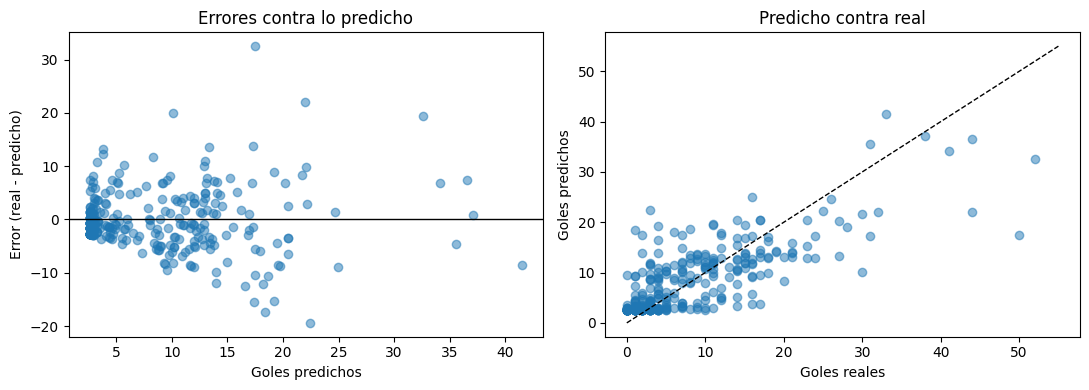

,n,pred_media,real_media,sesgo,mae
rango_pred,,,,,
"(-1, 4]",145,2.82,2.50,-0.32,2.17
"(4, 8]",41,5.42,5.71,0.29,3.29
"(8, 12]",59,10.14,8.80,-1.35,4.69
"(12, 60]",80,17.59,17.60,0.01,6.72


In [8]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Aquí, y solo aquí, se toca el test
tonto.fit(X_tr, y_tr)
simple.fit(X_tr, y_tr)
mejor = busqueda.best_estimator_      # ya reentrenado con todo train

pred_te = {'Tonto': tonto.predict(X_te),
           'Simple': simple.predict(X_te),
           'Ensamble': mejor.predict(X_te)}

def metricas(y_true, y_pred):
    return pd.Series({'RMSE test': mean_squared_error(y_true, y_pred) ** 0.5,
                      'MAE test': mean_absolute_error(y_true, y_pred),
                      'R2 test': r2_score(y_true, y_pred)})

resultados = pd.DataFrame({k: metricas(y_te, p) for k, p in pred_te.items()}).T
resultados['RMSE validación'] = [rmse_tonto.mean(), rmse_simple.mean(), -busqueda.best_score_]
display(resultados.round(2))

# Dónde se equivoca el ensamble
res = df.loc[~es_train, ['Players', 'anio', 'Goals', 'Goals_next']].copy()
res['pred'] = pred_te['Ensamble']
res['error'] = res['Goals_next'] - res['pred']       # positivo = el modelo se quedó corto
res['abs_error'] = res['error'].abs()

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(res['pred'], res['error'], alpha=0.5)
ax[0].axhline(0, color='k', lw=1)
ax[0].set_xlabel('Goles predichos'); ax[0].set_ylabel('Error (real - predicho)')
ax[0].set_title('Errores contra lo predicho')
ax[1].scatter(res['Goals_next'], res['pred'], alpha=0.5)
ax[1].plot([0, 55], [0, 55], 'k--', lw=1)
ax[1].set_xlabel('Goles reales'); ax[1].set_ylabel('Goles predichos')
ax[1].set_title('Predicho contra real')
plt.tight_layout(); plt.show()

# Errores según lo que el modelo PREDICE (no según lo real: agrupar por el valor real
# siempre muestra "se queda corto en lo alto y se pasa en lo bajo", aunque el modelo sea justo)
res['rango_pred'] = pd.cut(res['pred'], bins=[-1, 4, 8, 12, 60])
res.groupby('rango_pred', observed=True).agg(
    n=('error', 'size'), pred_media=('pred', 'mean'), real_media=('Goals_next', 'mean'),
    sesgo=('error', 'mean'), mae=('abs_error', 'mean')).round(2)


**Comparación contra los modelos de comparación** (RMSE, en goles):

| Modelo | Métrica (validación) | Métrica (test) |
|---|---|---|
| Tonto | 9.46 | 8.87 |
| Simple | 5.73 | 5.49 |
| Ensamble | 6.16 | 5.55 |

En test, el MAE es 6.81 (tonto), 3.68 (simple) y 3.89 (ensamble), y el R² es -0.01, 0.61 y 0.61.

**Dónde falla el modelo:**

- **El ensamble no le gana al simple.** En test queda prácticamente empatado (5.55 vs. 5.49) y en validación pierde (6.16 vs. 5.73). Con estos datos no se justifica la complejidad extra. Nuestra hipótesis es que la relación entre los goles de una temporada y la siguiente es casi lineal, que un árbol la aproxima por escalones y que con ~700 filas el bosque no tiene cómo ganar; no lo probamos. El modelo simple y el ensamble se comparan con las mismas métricas y no se eligió con el test.
- **El error crece con los goles esperados.** El MAE pasa de 2.2 goles cuando el modelo predice 4 o menos, a 3.3, 4.7 y 6.7 cuando predice más de 12. En la gráfica de errores contra lo predicho se ve un abanico que se abre hacia la derecha.
- **No hay un sesgo sistemático:** el error promedio por rango de predicción es pequeño (entre -1.4 y +0.3 goles). El rango de 8 a 12 goles es el que más se pasa (predice 10.1 y el real es 8.8). Por eso el error se debe más al azar de los goles de una temporada que a un modelo que se quede corto o largo siempre.
- **Piso en las predicciones bajas:** el modelo casi nunca predice menos de ~2.5 goles, aunque el jugador termine en 0, y en las temporadas más extremas (más de 40 goles reales) se queda lejos (predice entre ~17 y ~37).

## 7. Análisis sin respuestas

**Ruta elegida: A, agrupar (k-Means).** Se agrupan las temporadas de jugador por su perfil de rendimiento (partidos, goles, asistencias y rating), con las columnas escaladas y todo ajustado solo con train; los grupos de test se asignan después con ese mismo ajuste (no se ajusta nada con test). Se eligió agrupar y no PCA porque con solo cuatro columnas un resumen en ejes aporta poco y los grupos se pueden cruzar directamente con el error del modelo en la sección 8.

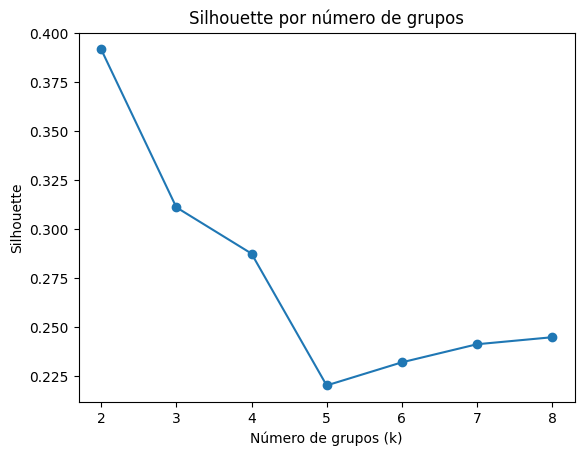

{2: np.float64(0.392), 3: np.float64(0.311), 4: np.float64(0.288), 5: np.float64(0.22), 6: np.float64(0.232), 7: np.float64(0.241), 8: np.float64(0.245)}


In [14]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Ruta A: agrupar temporadas de jugador por su perfil de rendimiento.
# Se escala primero (partidos y goles tienen magnitudes distintas) y todo se
# ajusta con train; los grupos de test se asignan después con ese mismo ajuste.
columnas_grupos = ['Matches', 'Goals', 'Assists', 'Seasons Ratings']
escalador = StandardScaler().fit(X_tr[columnas_grupos])
Z_tr = escalador.transform(X_tr[columnas_grupos])
Z_te = escalador.transform(X_te[columnas_grupos])

sil = {}
for k in range(2, 9):
    km_k = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Z_tr)
    sil[k] = silhouette_score(Z_tr, km_k.labels_)

plt.plot(list(sil), list(sil.values()), marker='o')
plt.xlabel('Número de grupos (k)'); plt.ylabel('Silhouette')
plt.title('Silhouette por número de grupos')
plt.show()
print({k: round(v, 3) for k, v in sil.items()})

In [10]:

K = 4   
km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Z_tr)

perfil = X_tr[columnas_grupos + ['goles_por_partido']].copy()
perfil['grupo'] = km.labels_
perfil['Goals_next'] = y_tr.values
tabla = perfil.groupby('grupo').agg(
    tamaño=('Goals', 'size'),
    partidos=('Matches', 'mean'), goles=('Goals', 'mean'),
    asistencias=('Assists', 'mean'), rating=('Seasons Ratings', 'mean'),
    goles_siguiente=('Goals_next', 'mean')).round(2)
tabla

,tamaño,partidos,goles,asistencias,rating,goles_siguiente
grupo,,,,,,
0,148,17.77,1.76,1.21,6.79,4.46
1,147,44.47,12.47,10.46,7.31,12.22
2,358,40.03,5.15,3.14,6.98,5.67
3,60,45.95,32.92,10.60,7.77,25.95


**Por qué K = 4:** el silhouette es más alto con k=2 (0.39) y baja con k=3 (0.31), k=4 (0.29) y k=5 (0.22), pero el silhouette sugiere y nosotros decidimos. Con k=2 queda un solo grupo de 192 filas (~20 goles de promedio) que mezcla a los de ~33 goles con los de ~12; con k=3 esa mezcla sigue en un grupo de 151 filas. Con k=4 se separan los 60 goleadores de élite, y es el último valor antes de la caída fuerte del silhouette en k=5. Un silhouette de 0.29 es modesto: los grupos se solapan y el rendimiento es más un gradiente que categorías naturales, así que se usan como segmentos descriptivos.

**Interpretación** (el dataset no trae posición, por eso los grupos se describen por rendimiento, no por rol):

| Grupo | Nombre en palabras del negocio | Qué lo caracteriza | Tamaño |
|---|---|---|---|
| 0 | Jugadores de rotación | ~18 partidos, 1.8 goles, 1.2 asistencias, rating 6.8; al año siguiente promedian 4.5 goles | 148 (21%) |
| 1 | Ofensivos regulares | Titulares (44 partidos) con 12.5 goles y 10.5 asistencias, rating 7.3; al año siguiente promedian 12.2 goles | 147 (21%) |
| 2 | Titulares de aporte moderado | 40 partidos, 5.2 goles y 3.1 asistencias, rating 7.0; al año siguiente promedian 5.7 goles | 358 (50%) |
| 3 | Goleadores de élite | 46 partidos, 32.9 goles y 10.6 asistencias, rating 7.8; al año siguiente promedian 26.0 goles | 60 (8%) |

Tamaños sobre las 713 filas de train.

## 8. Conexión entre las dos partes

*Lo que distingue un buen Proyecto 2 de dos tareas pegadas. Por ejemplo: ¿el modelo se equivoca más en algún grupo? ¿Los ejes de PCA coinciden con las columnas más importantes del modelo? ¿Los grupos sugieren una columna nueva?*

,n,goles_reales,sesgo,mae,rmse,mae_relativo
grupo,,,,,,
0,52,5.48,0.74,3.71,6.24,0.68
1,64,10.98,-1.07,4.84,6.47,0.44
2,187,5.11,-0.64,3.17,4.30,0.62
3,22,26.41,1.67,7.68,9.15,0.29


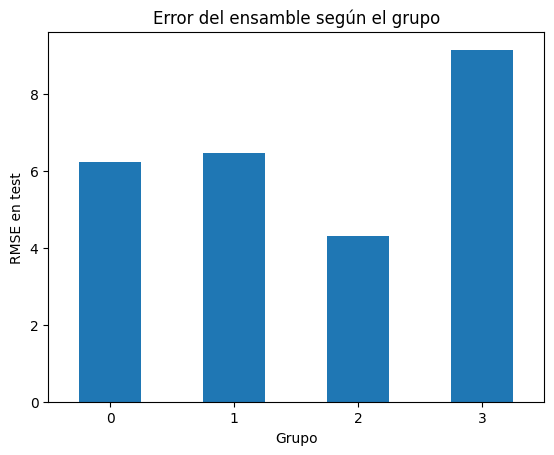

In [13]:
# Asignar a cada fila de test el grupo (calculado con train) y cruzar con el error
res['grupo'] = km.predict(Z_te)

por_grupo = res.groupby('grupo').agg(
    n=('error', 'size'),
    goles_reales=('Goals_next', 'mean'),
    sesgo=('error', 'mean'),                  # positivo = el modelo se queda corto
    mae=('abs_error', 'mean'),
    rmse=('error', lambda s: np.sqrt((s ** 2).mean())))
por_grupo['mae_relativo'] = por_grupo['mae'] / por_grupo['goles_reales']   # error por gol esperado
por_grupo = por_grupo.round(2)
display(por_grupo)

por_grupo['rmse'].plot.bar(rot=0)
plt.ylabel('RMSE en test'); plt.xlabel('Grupo')
plt.title('Error del ensamble según el grupo')
plt.show()

**Lo que aprendimos al cruzar ambas partes** (error del ensamble en test, por grupo):

- **En goles, los goleadores de élite son donde más falla** (RMSE 9.2 y MAE 7.7, contra 4.3 y 3.2 en los titulares de aporte moderado). Pero es un error proporcionalmente menor: unos 0.29 goles de error por gol esperado, contra 0.62-0.68 en los grupos de rotación y de aporte moderado. Es decir, al goleador se le yerra por mucho en términos absolutos, pero se le predice relativamente mejor que al jugador de pocos goles.
- **El grupo de rotación es el más difícil en términos relativos:** su RMSE (6.2) es mayor que sus goles promedio del año siguiente (5.5). Nuestra hipótesis es que su rol del año siguiente (si se vuelve titular o no) no está en ninguna columna; no lo verificamos.
- **El sesgo por grupo es pequeño** (entre -1.1 y +1.7 goles). En élite el modelo se queda algo corto (+1.7), pero son solo 22 filas de test y ese número es inestable; no se saca una conclusión fuerte.
- **Los grupos sugieren qué falta:** variables que expliquen el rol y la oportunidad de jugar (edad, posición, minutos, lesiones). Hoy el modelo ve el rendimiento pasado, no el contexto del jugador.
- **Uso práctico:** una predicción del modelo para un goleador de élite debe leerse con un margen de varios goles; para un jugador de rotación, con prudencia aún mayor en términos relativos.

## 9. Conclusiones y límites

**Respuesta a la pregunta.** Sí se puede predecir en parte cuántos goles anotará un jugador de élite la temporada siguiente. El modelo simple (regresión lineal) tiene un RMSE de 5.49 y un MAE de 3.68 goles en test (R² 0.61), contra 8.87 y 6.81 del modelo tonto, una reducción de ~38% del error. El ensamble no mejora (RMSE 5.55): la diferencia con el simple es de 0.06 goles, mucho menor que la variación entre pliegues de validación (~0.7), así que no hay evidencia de que uno supere al otro y conviene quedarse con el simple. El error se concentra en términos absolutos en los goleadores de élite (RMSE 9.2), aunque relativamente es menor ahí que en los jugadores de rotación. La confianza es moderada: el test tiene 325 filas de tres temporadas, y el grupo de élite apenas 22.

**Qué no se puede concluir.** Los datos son 165 jugadores de élite de las grandes ligas, así que el modelo no dice nada de jugadores promedio, de ligas menores ni de juveniles. Para entrar al análisis un jugador necesita una temporada siguiente registrada, por lo que quienes se retiraron o salieron de la muestra no aparecen (sesgo de supervivencia). No hay edad, posición, minutos ni lesiones, y no está documentado de dónde sale `Seasons Ratings` ni qué competiciones cuentan los goles. Las variables que ayudan a predecir no son causas: que los goles previos predigan los siguientes no significa que forzar goles hoy cambie el futuro. Los grupos describen perfiles de rendimiento, no roles. No se usó información de la temporada que se predice como variable (se descartó `cambio_equipo`), pero el equipo (`Teams`) sí es el de la temporada N. La validación cruzada interna agrupa por jugador pero no respeta el orden del tiempo (solo el test final lo hace), y las "primeras temporadas registradas" no son debuts reales.

**Qué haría falta para mejorarlo.** Edad, posición, minutos jugados, historial de lesiones y métricas como los goles esperados (xG), que reducen el azar de los goles; una muestra más amplia que incluya jugadores que no son estrellas y que conserve a quienes salen de las grandes ligas; más temporadas de test para que los grupos pequeños (como el de élite) pesen menos; y probar un modelo de boosting además del bosque.

## 10. Lista antes de entregar

- [x] ¿Todo lo que se calcula con los datos está **dentro** del `Pipeline`, y el `Pipeline` dentro de la validación?
- [x] ¿Está escrito **por qué** esa métrica?
- [x] ¿Hay modelo tonto y modelo simple para comparar?
- [x] ¿La búsqueda de opciones dice qué, en qué rango y por qué?
- [x] ¿Cada grupo tiene nombre y descripción en palabras del negocio?
- [x] ¿El test se tocó una sola vez?
- [x] ¿Hay un párrafo de lo que **no** se puede concluir?
- [x] ¿El notebook corre de arriba a abajo sin errores (`Restart & Run All`)?

**Entrega: viernes 16 de octubre.** Parcial II: jueves 22 de octubre (sesiones 11 a 21).

## 11. Bitácora de colaboración con IA

- Se hizo la consulta para verificar que el dataset del Proyecto 1 si fuera bueno para el Proyecto 2 y encontrar puntos de mejora.
- Se utilizo como apoyo en creación de gráficas y bloque sde código muy pesados de realizar, siempre planteando en el promt el concepto y lo que se buscaba alcanzar. Solo se buscaba entender bien el orden y significado de cada linea de codigo para poder realizarla. 
- Algo para lo que se utilizo mucho y fue de gran ayuda fue para escribir la respuesta en los markdown (no la redaccion), asi quedaba ordenado para mejor entendimiento del lector, con un estilo amigable. Esto principalmente a la hora de resaltar alguna variable o realizar alguna tabla comparativa, se dio a la IA el analisis hecho por la persona y resultados encontrados de forma algo desordenada, y la IA ayudo a que se viero mejor
- Por ultimo, se utilizo la IA para encontrar la informacion clave de las Hojas de Trabajo y presentaciones de la clase, para facilitar el acceso a la información, ahorrar tiempo y entender los conceptos de cada una.  